# Molecular Dynamics and Statistical Mechanics



Please complete each task/part by modifying or adding code/markdown cells within each section.

# Section One - Understanding the Code

### <font color='red'>Please put your name below</font>



Kythreotis Stefanos

## Part 1

Below is a (relatively) simple code designed to run a molecular dynamics simulation of Lennard-Jones particles in the microcanonical ensemble, i.e. at constant *N*, *V*,and *E*.  While this code is completely functional, it is not well-documented. To begin, please add comments in the code to clearly document what the program is doing.  Perform this for all functions and for all code within each function.  You do not need to comment on the lines containing the  `@jit`  statements.

In [13]:
import numpy as np #imports numpy library
from numba import double, jit, types #imports numba tools to turn python from interpreter to compiler to speed up run time
import matplotlib.pyplot as plt #imports Matplotlib for plotting and visualising simulation results

def getParams(rho): #defines a function that calculates simulation parameters using density
    params = np.zeros(4) #creates an array of four parameters initially set at zero
    rCut = 2.5 #defines the cut-off distance, beyond this distance any particle interactions are neglected
    params[0] = rCut #stores the cut-off distance of the first element
    params[1] = rCut*rCut  #stores and calculates the squared of the cut-off distance
    rc2i = 1.0/params[1] #calculates the inverse of the squared cut-off distance
    rc6i = rc2i*rc2i*rc2i #calculates the sixth power of the cut-off distance
    params[2] = rc6i*(rc6i-1.0) #stores and calculates the twelveth power of the cut-off distance subtracted by the sixth 
    params[3] = (16.0/3.0)*np.pi*rho*rho*((2.0/3.0)*(np.power(rCut,-9.0))-np.power(rCut,-3.0)) #stores and calculates a density-dependent correction term using the cutoff distance and its inverse third and ninth powers 
    return params #returs the array containing the four calculated simulation parameters

def getData(): #defines a function that initiliases the dictionary used to store simulation data
    data = {} #creates an empty python dictionary to store simulation results
    data['eKin'] = [] #creates an empty list to store kinetic energy at each simulation step
    data['ePot'] = [] #creates an empty list to store potential energy at each simulation step
    data['pres'] = [] #creates an empty list to store the pressure calculated during simulation
    data['temp'] = [] #creates an empty list to store the temperature at each simulation step
    data['time'] = [] #creates an empty list to store the simulation time at each time step
    return data #returns the dictionary containing the empty lists ready to store simulation results
    

@jit(types.Tuple((double, double))(double[:,:]),nopython=True) #uses numba to accelerate the function
def getKinetic(V): #defines a function that calculates kinetic energy and temperature from particle velocities
    
    n_atoms = len(V[0]) #determines the total number of atoms by counting the velocity components in the x-direction
    kTot = 0.0 #sets the total kinetic energy accumulator initially zero
    temp = 0.0 #sets the temperature initially zero
    
    for i in range(n_atoms): #creates a loop and loops through every atom
        kTot += V[0,i]*V[0,i] + V[1,i]*V[1,i] + V[2,i]*V[2,i] #adds the squared velocity components in the x,y, and z directions to the total kinetic accumulator 
        
    kTot = kTot / 2 #calculates the total kinetic energy(assuming particle mass = 1) by dividing by two
    
    temp = (2 * kTot) / (3 * n_atoms) #calculates the temperature from the kinetic energy and number of atoms(assuming that the boltzman constant = 1)
    
    return kTot,temp #returrns the total kinetic energy and temperature
    

@jit(types.Tuple((double[:,:], double, double))(double[:,:], double[:], double[:]),nopython=True)
def lennardjones(U, box, params): #defines a function to calculate the Lennard Jones forces, potential and virial
    
    n_atoms = len(U[0]) #determines the total number of atoms using the x-coordinate

    f = np.zeros((3, n_atoms)) #ceates an array of zeros to store the x, y and z force componenets of each atom

    ePot = 0.0 #sets the potential energy initially at zero
    vir = np.zeros(3) #creates an array of the x, y and z direction to accumulate the virial contributions
    virTotal = 0.0 #sets the total virial contribution to zero

    for i in range(n_atoms): #creates a loop and loops through every atom as the first particle in an interacting pair
        for j in range(n_atoms): #creates a loop and loops through every atom again to identify possible interacting particle pairs
            
            if i > j: #allows 2 particles to collide only once, does not consider secondary and tertiary collisions from the sme 2 particles

                dx  = U[0,j] - U[0,i] #Calculates the separation between particles j and i in the x-direction
                dy  = U[1,j] - U[1,i] #Calculates the separation between particles j and i in the y-direction
                dz  = U[2,j] - U[2,i] #Calculates the separation between particles j and i in the z-direction

                dx  -= box[0] * np.rint(dx/box[0]) #Applies the minimum image convention in x to account for periodic boundary conditions 
                dy  -= box[1] * np.rint(dy/box[1]) #Applies the minimum image convention in yto account for periodic boundary conditions
                dz  -= box[2] * np.rint(dz/box[2]) #Applies the minimum image convention in x to account for periodic boundary conditions

                r2 = dx*dx + dy*dy + dz*dz #calculates the squared distance of the separation of 2 particles

                if(r2 < params[1]): #creates a conditional to check whether particles are closer than the squared off the cut-off distance
                
                    r2i = 1.0 / r2 #calculates the inverse of the squared separation distance
                    r6i = r2i*r2i*r2i #calculates the sixth power of the inverse square se[aration distance

                    ePot = ePot + r6i*(r6i-1.0) - params[2] #calculates the pair potential contribution, including a correction that shifts the potential to zero at the cutoff distance

                    ftmp = 48.0 * r6i*(r6i- 0.5) * r2i #calculates the scalar force by differentiating the negative potential with respect to distance
                    
                    fx = ftmp * dx #calculates the x component of the force between the 2 particles
                    fy = ftmp * dy #calculates the y component of the force between the 2 particles
                    fz = ftmp * dz #calculates the z component of the force between the 2 particles
                    
                    f[0,i] -= fx #updates the x component of the force on particle i
                    f[1,i] -= fy #updates the y component of the force on particle i
                    f[2,i] -= fz #updates the z component of the force on particle i
                    f[0,j] += fx #updates the x component of the force on particle j with the equal and opposite force
                    f[1,j] += fy #updates the y component of the force on particle j with the equal and opposite force
                    f[2,j] += fz #updates the z component of the force on particle j with the equal and opposite force
                    
                    vir[0] += fx * dx #accumulates the x direction virial contribution from this particular pair
                    vir[1] += fy * dy #accumulates the y direction virial contribution from this particular pair
                    vir[2] += fz * dz #accumulates the z direction virial contribution from this particular pair
                                 
    ePot = ePot * 4.0 #multiplies the pair potential contribution by 4 to obtain the Lennard-Jones potential energy in standard reduced units
    virTotal = np.mean(vir) #Calculates the average of the three directional virial contributions
    return f,ePot,virTotal #returns the force, potential energy, and the average virial contributions


def initialize_positions(n_atoms, rho): #defines a function to initialise the position of all atoms using the number of atoms and density
    
    pos = np.zeros((3, n_atoms)) #creates an array of 4 parameters, 3 of them are initially zero to store the x, y and z coordinates of every atom
    nPerDim = int(np.ceil(pow(n_atoms,(1.0/3.0)))) #calculates the number of grid points needed along each dimension to accomodate all atoms
    vol = n_atoms/rho #calculates the total simulation volume
    lenWhole = np.power(vol,(1.0/3.0)) #Calculates the side length of the cubic simulation box using L = V^(1/3)
    
    counter = 0 #initiliases a counter to keep track of how many atoms have been assigned positions
    for i in range(0,nPerDim): #creates a loop and loops through the grid positions in the x direction
        for j in range(0,nPerDim): #creates a loop and loops through the grid positions in the y direction
            for k in range(0,nPerDim): #creates a loop and loops through the grid positions in the z direction
                if (counter < n_atoms): #checks that the total number of assignes positions have not exceeded the total number of atoms
                    pos[0,counter] = (i+0.5)*lenWhole/nPerDim #assigns the x coordinate of the current atom, placing it at the centre of its grid cell
                    pos[1,counter] = (j+0.5)*lenWhole/nPerDim #assigns the y coordinate of the current atom, placing it at the centre of its grid cell
                    pos[2,counter] = (k+0.5)*lenWhole/nPerDim #assigns the z coordinate of the current atom, placing it at the centre of its grid cell
                    counter += 1 #increases the counter after succesfully assigning a particle position
    return pos #returns the array containing the initial position of all atoms

def initialize_box(n_atoms, rho): #defines a function that initialiazes the simulation box using the number of atoms and number density
    
    box = np.zeros(3) #creates an array of 3 elements to store the box lengths
    vol = n_atoms/rho #calculates the total simulation volume
    lenWhole = np.power(vol,(1.0/3.0)) #Calculates the side length of the cubic simulation box using L = V^(1/3)
    box[0] = box[1] = box[2] = lenWhole #assigns the box length to x = y = z
    return box #returns the box dimensions

def initialize_velocities(n_atoms,temp): #defines a function to initialize the velocity of all atoms using the number of atoms and temperature

    vel = np.random.normal(0.0,np.sqrt(temp),(3,n_atoms)) #creates random velocity of atoms from a Gaussian distribution with mean zero and standard deviation sqrt(T), for all three directions and all atoms
    mean = np.mean(vel,axis=1) #calculates the average velocities across all atoms in each direction
    for i in range(3): #creates a loop and loops through the x, y and z
        vel[i] -= mean[i] #subtracts the average velocity in each direction to eliminate the overall centre of mass motion
    return vel #returns the initial velocity array of all atoms

@jit(double[:,:](double[:,:], double, double),nopython=True)
def scale_velocities(vel,target,temp): #defines a function that rescales velocities to achieve the target temperature

    factor = np.sqrt(target/temp) #calculates the scaling factor using the square root of the ratio between target and current temperature
    return vel*factor #returns the adjusted velocities


def runSimulation(temperature, n_atoms, rho, n_steps_eq, n_steps_prod): #defines the main function to run a simulation using temperature, number of atoms, density, equilibration and production tests  
    
    pos = initialize_positions(n_atoms, rho) #sets the intial position of all atoms on the 3D grid
    box = initialize_box(n_atoms, rho) #generates the dimensions of the cube
    vel = initialize_velocities(n_atoms, temperature) #generates the initial velocities corresponding to the temperature
    params = getParams(rho) #Calculates and stores the Lennard-Jones parameters and density-dependent corrections
    data= getData() #Creates an empty dictionary to store simulation results such as energy, temperature, pressure and time
    
    
    if (box[0] < 2*params[0]): #checks whether the box length is less than twice the cut-off distance
        print("Box size too small. Try adding more atoms or reducing the density.") #if it is, it prints the size is smaller than it should
        return #stops the simulation if the box dimensions are unsuitable
    
    
    n_steps_tot = n_steps_eq + n_steps_prod #total steps is the accumulation of equilibration and production steps
    blockTemp = 500 #defines the number of simulation steps between temperature rescaling operations
    blockData = 50 #defines the number of simulation steps between data recording operations
    dt = 0.0005 #sets the simulation time step
    
    force,ePot,virial = lennardjones(pos,box,params) #calculates the initial forces, potential energies and virial using the lennard jones parameters
    tempBlock = 0.0 #initialises an accumulator to zero, used to sum the instantaneous temperatures over 500 simulation steps during equilibration
    presBlock = 0.0 #initialises an accumulator to zero, used to sum the calculated pressure values over 50 simulation steps before calculating their average
    
    print("Starting equilibration...") #displays a message indicating that the equilibration stage is starting
    
    for i in range(n_steps_tot): #starts the main simulation loop and repeats the molecular dynamics calculations for every time step
        
        if i == n_steps_eq: #checks whether the equilibration steps have finished
            print("Finished equilibration, beginning production...") # if equilibration finished, displays a message that it has and it begines production
        
        
        pos += vel * dt + 0.5 * force * dt * dt #updates the atoms positions using the velocity-Verlet integration equation  
        
        force0 = force[:] #creates a copy of the old forces before calculating the new forces at the updated atom positions
        
        force,ePot,virial = lennardjones(pos, box, params)  #recalculates forces, potential energy and virial using the updated atom positions
        
        vel += 0.5 * (force + force0) * dt #updates atom velocities using the average of the old and new forces (velocity-Verlet algorithm, assuming unit mass)
     
        kTot,temp = getKinetic(vel) #calculates the total kinetic energy and instanteneous temperature using the updated velocities 
        tempBlock += temp #accumulates the current temperature for the current temperature-rescaling block

        presBlock += (rho*temp) + (virial/(box[0]*box[1]*box[2])) + params[3] #accumulates the pressure contribution from particle motion, interparticle forces and the density-dependent tail correction
        
        if (i+1)%blockData == 0: #checks whether the current simulation step is a multiple of the data-recording interval
            data['eKin'].append(kTot) #stores the current total kinetic energy in the results dictionary
            data['ePot'].append(ePot) #stores the current total potential energy in the results dictionary
            data['temp'].append(temp) #stores the current instantaneous temperature in the results dictionary
            data['pres'].append(presBlock/blockData) #stores the average pressure over the last data-recording block
            data['time'].append((i+1)*dt) #stores the elapsed simulation time corresponding to the current simulation step
            presBlock = 0.0 #resets the accumulated pressure to zero for the next data-recording block
                                   
        if (i+1)%blockTemp == 0 and i < n_steps_eq: #checks whether 500 steps have passed and whether the simulation is still in the equilibration stage
            avgTemp = tempBlock/blockTemp #calculates the average temperature over the last temperature-rescaling block
            vel = scale_velocities(vel,temperature,avgTemp) #rescales atom velocities to bring the system closer to the target temperature
            tempBlock = 0.0 #resets the accumulated temperature to zero for the next temperature-rescaling block
     
        if (i+1)%5000 == 0 and (i+1) <= n_steps_eq: #checks whether 5000 steps have passed during equilibration
            print("{0:.2f}% done".format((i+1)*100/n_steps_eq)) #calculates and displays the percentage of equilibration completed
            
        if (i+1)%5000 == 0 and (i+1) > n_steps_eq: #checks whether 5000 steps have passed during production
            print("{0:.2f}% done".format((i+1-n_steps_eq)*100/n_steps_prod)) #calculates and displays the percentage of production completed
    
    return data #returns the dictionary containing all the recorded simulation results


## Part 2

Based on your understanding of the code, write an expression below that relates temperature to particle velocities in the cell below (using markdown).

$$
T = \sum_{i=1}^{n}
\frac{(v_x^2+v_y^2+v_z^2)_i}{3n}
$$
where in reduced units $$m = k_B = 1$$


## Part 3

Test your documented code by running a simulation.  The code snippet below shows a sample input for the program; you may wish to run the simulation for more/fewer timesteps or with more/fewer particles.  In general, you will obtain more statistically meaningful results with longer/larger simulations (i.e. more data!), but it will take longer to run. The density $N/V$ should be in the range 0.05-0.3 and the temperature $T^*$ should be in the range 1.5-2.0.

In the cells below, use python's graphing packages to show that after a brief "equilibration" period, your code leads to stable average values of kinetic/potential energy, temperature, and pressure. Verify that the total energy is conserved during the "production" portion of the simulation.

In [14]:
temperature = 1.5
n_atoms = 200
density = 0.2
eq_steps = 5000
prod_steps = 5000
data = runSimulation(temperature, n_atoms, density, eq_steps, prod_steps)

Starting equilibration...
100.00% done
Finished equilibration, beginning production...
100.00% done


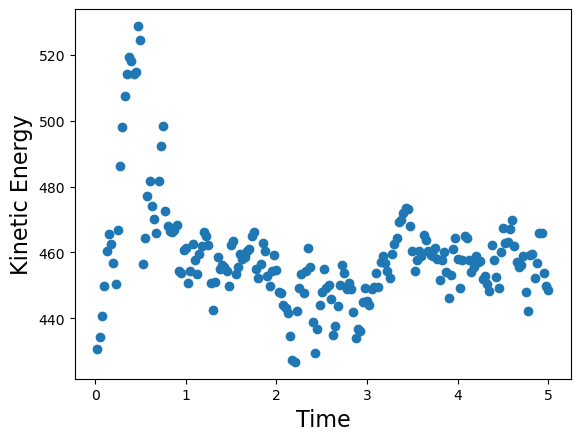

In [15]:
# example plot
plt.scatter(data["time"], data["eKin"])
plt.xlabel("Time", fontsize=16)
plt.ylabel("Kinetic Energy", fontsize=16)
plt.show()

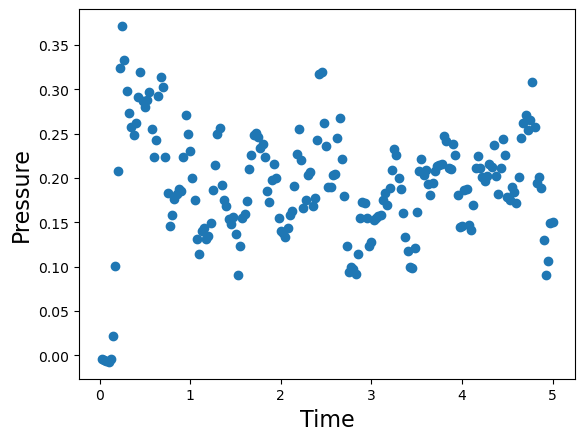

In [16]:
#example plot
plt.scatter(data["time"], data["pres"])
plt.xlabel("Time", fontsize=16)
plt.ylabel("Pressure", fontsize=16)
plt.show()

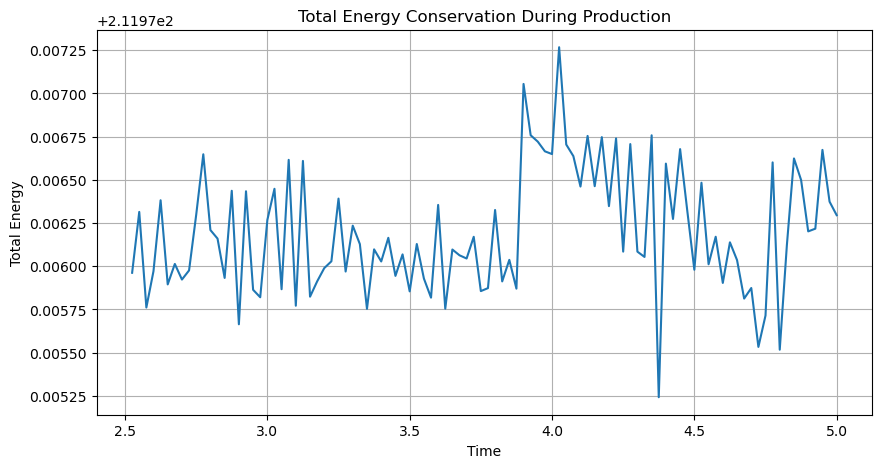

Average total energy: 211.9761942711627
Maximum energy deviation: 0.001073052417694953
Maximum percentage deviation: 0.0005062136441237784 %


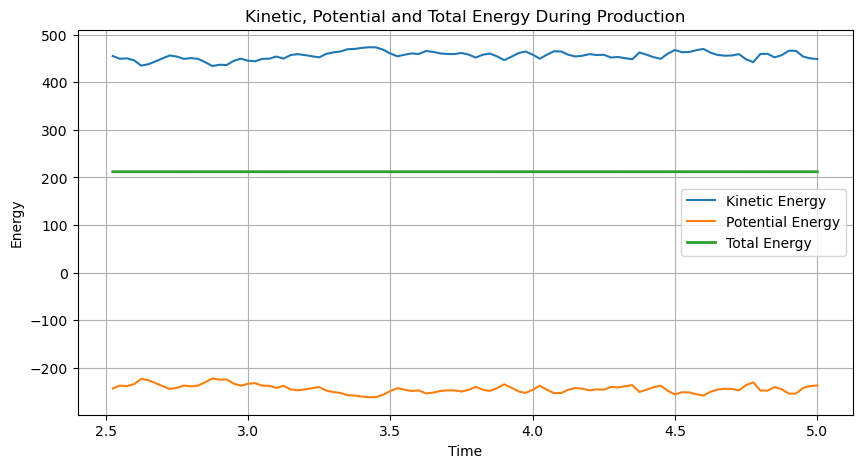

In [17]:
# Calculate total energy by adding kinetic and potential energy
total_energy = np.array(data['eKin']) + np.array(data['ePot'])

# Calculate the number of recorded equilibration data points
eq_points = eq_steps // 50

# Extract total energy during production only
production_energy = total_energy[eq_points:]

# Extract corresponding simulation times
production_time = np.array(data['time'])[eq_points:]

plt.figure(figsize=(10,5))

plt.plot(production_time, production_energy)

plt.xlabel('Time')
plt.ylabel('Total Energy')
plt.title('Total Energy Conservation During Production')

plt.grid(True)
plt.show()

# Calculate the average total energy during production
avg_energy = np.mean(production_energy)

# Calculate the maximum deviation from the average energy
max_deviation = np.max(np.abs(production_energy - avg_energy))

# Calculate percentage deviation
percentage_deviation = (max_deviation / abs(avg_energy)) * 100

print("Average total energy:", avg_energy)
print("Maximum energy deviation:", max_deviation)
print("Maximum percentage deviation:", percentage_deviation, "%")

plt.figure(figsize=(10,5))

plt.plot(production_time, np.array(data['eKin'])[eq_points:], label='Kinetic Energy')
plt.plot(production_time, np.array(data['ePot'])[eq_points:], label='Potential Energy')
plt.plot(production_time, production_energy, label='Total Energy', linewidth=2)

plt.xlabel('Time')
plt.ylabel('Energy')
plt.title('Kinetic, Potential and Total Energy During Production')

plt.legend()
plt.grid(True)
plt.show()

## Part 4

We typically use a "cut-off" radius $r_{c}$ to speed up calculation - particles separated by distances larger than this value do not exert forces on one another.  However, $r_{c}$ cannot be larger than half of the box length.  Why is that?  Answer in the cell below (using markdown).


The cut-off radius cannot be larger than half the box length because of the minimum image convention and periodic boundary conditions.

The simulation uses periodic images of the box to represent an infinite system. When calculating the distance between two particles, we consider only the closest periodic image.

If the cut-off radius exceeds half the box length, a particle may interact with multiple periodic images of the same particle. This can lead to double-counting of interactions and incorrect force and energy calculations.


## Part 5

By examining your code, explain how the pressure of the Lennard-Jones fluid is calculated. How does the pressure arise in the system?


The pressure of the Lennard-Jones fluid is calculated using the virial equation of state:

$$
\boxed{
P = \rho T + \frac{\mathrm{virial}}{L_x L_y L_z} + \mathrm{params}[3]
}
$$

where:

- The first contribution, $\rho T$, represents the ideal-gas contribution, arising from the thermal motion of the particles, based on $PV=Nk_BT$.
- The second contribution, $W/(3V)$, is the virial contribution, accounting for the forces and interactions between particles.
- The third contribution, $P_{\mathrm{tail}}$, is the tail correction. Since the simulation uses a finite cut-off distance, interactions between particles separated by distances greater than this cutoff are neglected. However, these particles still exert weak attractive and repulsive forces. The tail correction estimates the contribution of these neglected interactions to the pressure. It is generally negative because the attractive interactions dominate at larger distances.

# Section Two - Connecting with Reality

Your program operates in "reduced units."  These units are related to real quantities through the following equations:

$$ T^* = \frac{k_B T}{\epsilon} $$

$$ \rho^* = \sigma^3 \rho $$

$$ t^* = t \sqrt{\frac{\epsilon}{m\sigma^2}} $$

where $m$ is the mass of the particles. The code (as provided) implicitly uses $\sigma = 1$ and $\epsilon=1$. The reason for using these vales is based on the principle of corresponding states; any two fluids interacting through a LJ potential behave in exactly the same way, provided you compare their properties in the appropriately reduced units. For instance consider fluid $A$ with $\sigma_A = 1$ and fluid $B$ with $\sigma_B = 2$. You could use the results of your simulation with $\sigma = 1$ (i.e. fluid $A$ at a given density (say $\rho_A^* = 0.5$) to determine the properties of the other fluid at a different density ( $\rho_B^* = 0.5/\sigma_B^3 = 0.125$)




## Part Six

Based on the definitions of reduced units above, provide a definition of the reduced pressure in the cell below (in markdown).

$$
P^* = \frac{\sigma^3 P}{\epsilon}
$$


## Part Seven

Let's say we're interested in the properties of methane, whose Lennard-Jones parameters are shown below.

$$ \sigma = 3.73 \text{Ang.}$$


$$ \frac{\epsilon}{k_B} = 147.9 K $$

Based on this data, what was the size of the timestep you used in Part 3 above in real units (seconds)? How long was your simulation, also in real units? What were the real values of temperature and pressure of your system (in $K$ and bar, respectively)?  Answer in the cell below.



The Lennard-Jones parameters for methane are:

$$
\sigma=3.73\times10^{-10}\ \mathrm{m}
$$

$$
\frac{\epsilon}{k_B}=147.9\ \mathrm{K}
$$

The molecular mass of methane is:

$$
m=16.04\ \mathrm{amu}
=16.04(1.66054\times10^{-27})
$$

$$
m=2.663\times10^{-26}\ \mathrm{kg}
$$

### 1. Real timestep

The conversion from reduced time to real time is:

$$
\Delta t=\Delta t^*\sqrt{\frac{m\sigma^2}{\epsilon}}
$$

Since:

$$
\epsilon=147.9k_B
=147.9(1.380649\times10^{-23})
$$

$$
\epsilon=2.0426\times10^{-21}\ \mathrm{J}
$$

Substituting:

$$
\Delta t=0.0005
\sqrt{
\frac{
(2.663\times10^{-26})(3.73\times10^{-10})^2
}{
2.0426\times10^{-21}
}
}
$$

$$
\boxed{\Delta t=6.736\times10^{-16}\ \mathrm{s}}
$$

### 2. Total simulation time

The total number of simulation steps is:

$$
N_{\mathrm{total}}=N_{\mathrm{eq}}+N_{\mathrm{production}}
$$

$$
N_{\mathrm{total}}=5000+5000=10000
$$

Therefore:

$$
t_{\mathrm{total}}=N_{\mathrm{total}}\Delta t
$$

$$
t_{\mathrm{total}}=10000(6.736\times10^{-16})
$$

$$
\boxed{t_{\mathrm{total}}=6.736\times10^{-12}\ \mathrm{s}}
$$

### 3. Real temperature

The reduced temperature is defined as:

$$
T^*=\frac{k_BT}{\epsilon}
$$

Rearranging:

$$
T=T^*\frac{\epsilon}{k_B}
$$

Substituting:

$$
T=1.5(147.9)
$$

$$
\boxed{T=221.85\ \mathrm{K}}
$$

### 4. Reduced pressure

The pressure equation used in the simulation is:

$$
P^*=\rho^*T^*+\frac{W}{3V^*}+P_{\mathrm{tail}}^*
$$

The pressure tail correction is:

$$
P_{\mathrm{tail}}^*=
\frac{16\pi}{3}(\rho^*)^2
\left[
\frac{2}{3(r_c^*)^9}
-\frac{1}{(r_c^*)^3}
\right]
$$

Using:

$$
\rho^*=0.2,\qquad r_c^*=2.5
$$

$$
P_{\mathrm{tail}}^*=
\frac{16\pi}{3}(0.2)^2
\left[
\frac{2}{3(2.5)^9}
-\frac{1}{(2.5)^3}
\right]
$$

$$
P_{\mathrm{tail}}^*=-0.042776
$$

Assuming the virial contribution is zero:

$$
P^*=(0.2)(1.5)+0-0.042776
$$

$$
\boxed{P^*=0.257224}
$$

### 5. Real pressure

The reduced pressure is converted into real pressure using:

$$
P=\frac{\epsilon}{\sigma^3}P^*
$$

For methane:

$$
P=393.48P^*\ \mathrm{bar}
$$

Therefore:

$$
P=393.48(0.257224)
$$

$$
\boxed{P=101.21\ \mathrm{bar}}
$$
The virial is not actually 0, it generally has a negative value because attractive forces dominate. The virial does not have a fixed value, we have to find it analytically as it depends on where the atoms are found at each instant.

## Part Eight

The (truncated) virial equation of state for methane is given below:

$$ P = \rho R T \left ( 1 + B \rho_r \right ) $$

$$ B = B_0 + \frac{B_1}{T_r} + \frac{B_2}{T_r^2} + \frac{B_3}{T_r^3}$$

$$ B_0 = 0.440 \\ B_1 = -1.171 \\ B_2 = -0.236 \\ B_3 = -0.210 $$

where $\rho_r \equiv \rho/\rho_c$ is the density relative to the critical density and $T_r = T/T_c$ is the temperature relative to the critical temperature. For methane, $\rho_c = 10.1 mol/L$ and $T_c = 190.6 K$. 
In the cell(s) below, verify the accuracy of this equation at a reduced temperature of $T^* = 2.0$. For what values of $\rho$ does it break down? To answer this question, you will need to run the simulation at several densities in the range of $\rho = 0.05-0.3$. Compare the pressure obtained in simulations to that predicted by the virial equation. Create a plot of simulated and predicted pressures as a function of density. Perform all calculations in reduced units and explain your results.

In [60]:
def truncated_virial(T_star = 2, Tc = 190.6):
  Tk=T_star*147.9 #Tstar*e/kb
  Tr = Tk/Tc

  B0 = 0.440
  B1 = -1.171
  B2 = -0.236
  B3 = -0.210
  B = B0 + B1/(Tr) + B2/((Tr)**2) + B3/((Tr)**3)

  return B

def virial_eos_press(rho_star, T_star, Tc, R):
  B = truncated_virial(T_star, Tc)

  rho_c_star = 10.1*(6.022*(10**(23))*(3.73*10**(-10))**3)/(1e-3)
  P_vir = rho_star*1.0*T_star*(1+(B*(rho_star/rho_c_star))) #R=1 in reduced units

  return P_vir

print(truncated_virial(T_star, Tc))

-0.46870581578354215


In [61]:
def density_sweep(rho_vals, temp, n_atoms, n_steps_eq, n_steps_prod, block_data=50):
  prod_start_idx = n_steps_eq//block_data
  simulation_pressure_mean = []
  simulation_pressure_error = []
  virial_pressure = []
  all_data = {}

  for rho in rho_vals:
    data = runSimulation(temp, n_atoms, rho, n_steps_eq, n_steps_prod)
    all_data[rho] = data

    p_production = np.asarray(data["pres"][prod_start_idx:], dtype=float)
    simulation_pressure_mean.append(np.mean(p_production))
    simulation_pressure_error.append(np.std(p_production))
    virial_pressure.append(virial_eos_press(rho, T_star=2.0, Tc=190.6, R=1)) #rho_c =mol/L, Tc = Kelvin, R in L*bar/mol*K

  return (
      np.asarray(rho_vals), 
      np.asarray(simulation_pressure_mean), 
      np.asarray(simulation_pressure_error), 
      np.asarray(virial_pressure), 
      all_data
  )

Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.0

100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Starting equilibra

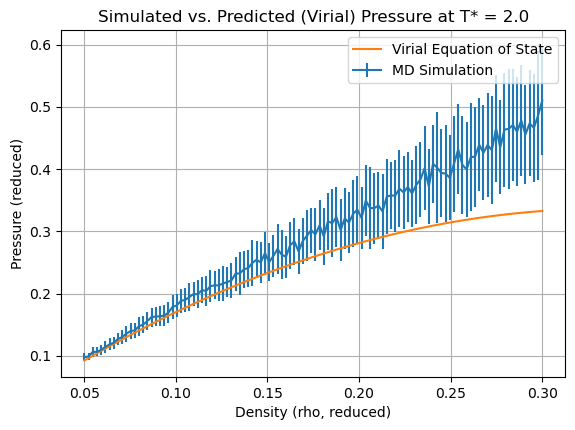

In [62]:
rho_vals = np.linspace(0.05, 0.3, 110)
rho_vals, simulation_pressure_mean, simulation_pressure_error, virial_pressure, all_data = density_sweep(
    rho_vals, 
    temp=2.0, 
    n_atoms=200,
    n_steps_eq=5000, 
    n_steps_prod=10000
)

rho_space = np.linspace(min(rho_vals), max(rho_vals), 200)
vir_space = [virial_eos_press(r, T_star=2.0, Tc=190.6, R=1) for r in rho_space]
plt.figure(figsize=(6.5, 4.5))
plt.errorbar(rho_vals, simulation_pressure_mean, yerr=simulation_pressure_error, label='MD Simulation')
plt.plot(rho_space, vir_space, label='Virial Equation of State')
plt.xlabel("Density (rho, reduced)")
plt.ylabel("Pressure (reduced)")
plt.title("Simulated vs. Predicted (Virial) Pressure at T* = 2.0")
plt.legend()
plt.grid(True)
plt.show()

In [63]:
# Converting reduced pressure to pressure in bar

to_bar = (147.9*1.380649e-23)/((3.73e-10)**3*1e5)

sim_p_bar = np.asarray(simulation_pressure_mean)*to_bar

sim_err_bar = np.asarray(simulation_pressure_error)*to_bar

virial_p_bar = np.asarray(virial_pressure)*to_bar

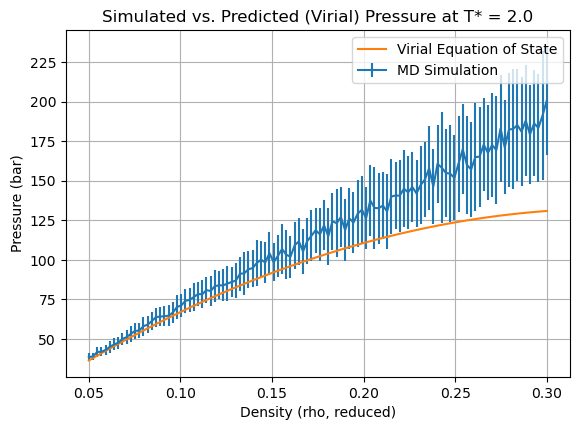

In [64]:
plt.figure(figsize=(6.5, 4.5))
plt.errorbar(rho_vals, sim_p_bar, yerr=sim_err_bar, label='MD Simulation')

plt.plot(rho_vals, virial_p_bar, label='Virial Equation of State')
plt.xlabel("Density (rho, reduced)")
plt.ylabel("Pressure (bar)")
plt.title("Simulated vs. Predicted (Virial) Pressure at T* = 2.0")
plt.legend()
plt.grid(True)
plt.show()

The molecular dynamics (MD) simulations and the truncated virial equation of state show good agreement at low reduced densities (approximately 0.05–0.10). In this region, methane molecules are relatively far apart, meaning that intermolecular interactions have a smaller influence on the overall system behaviour. Consequently, the pressure approaches the ideal-gas prediction, and both methods produce similar results.

As the reduced density increases, the difference between the two predictions becomes more pronounced. At a reduced density of approximately 0.30, the MD simulation predicts a pressure of around 190 bar, whereas the truncated virial equation predicts approximately 130 bar. This difference arises because the truncated virial equation only accounts for the leading non-ideal correction through the second virial coefficient, which depends on temperature. Although this correction captures some effects of intermolecular interactions, it does not fully describe the increasingly complex molecular correlations that become important at higher densities.

In contrast, MD simulations calculate the pressure using the molecular velocities and intermolecular forces, allowing them to account for the interactions between particles throughout the simulation. This enables the MD method to capture non-ideal behaviour that is not fully represented by the truncated virial equation. The increasing difference between the two predictions therefore suggests that the truncated virial approximation becomes less effective as density increases. Including higher-order virial coefficients could potentially improve its predictions by accounting for additional molecular interactions and correlations.

Overall, the two methods agree reasonably well at low densities, but their predictions diverge as density increases. The MD simulations capture the pressure increase more strongly, highlighting the limitations of using a truncated virial equation at higher densities.

The error bars in the MD simulation represent the standard deviation of the instantaneous pressure measurements collected during the production stage of each simulation. They indicate the extent of pressure fluctuations around the calculated mean pressure, rather than the uncertainty in the mean itself. The magnitude of these fluctuations generally increases with density, as molecules become more closely packed and intermolecular forces become increasingly significant. This leads to larger variations in the virial contribution to the pressure. Therefore, the larger error bars at higher densities reflect the more pronounced pressure fluctuations associated with the increasingly non-ideal behaviour of the methane system.

## Part Nine

Now we are interested in comparing our simulation results to experimental values.  For a reduced temperature of $T^* = 2.0$, simulate a broader range of densities $\rho^* = 0.05 - 0.5$. Now, use the [NIST Chemistry WebBook](https://webbook.nist.gov/chemistry/fluid/) to obtain experimental values for the pressure of methane at the corresponding real temperature/densitites and plot this data alongside your simulation results and the predictions of the virial equation of state given above.  How does your simulation data compare over the range of densities? Are your simulations more or less accurate than the virial equation?

In [65]:
NIST_temp = 295.80 #kelvin
NIST_pressure = [0.000, 10.000, 20.000, 30.000, 40.000, 50.000, 60.000,
                 70.000, 80.000, 90.000, 100.000, 110.000, 120.000,
                 130.000, 140.000, 150.000, 160.000, 170.000, 180.000,
                 190.000, 200.000, 210.000, 220.000, 230.000, 240.000,
                 250.000] #bar
NIST_rho = [0.0000, 0.41393, 0.84282, 1.2871, 1.7469, 2.2222, 2.7128,
            3.2177, 3.7359, 4.2653, 4.8036, 5.3479, 5.8947, 6.4402,
            6.9806, 7.5122, 8.0317, 8.5361, 9.0233, 9.4917, 9.9403,
            10.369, 10.777, 11.166, 11.536, 11.887] #mol/L

In [66]:
sigma = 3.73e-10 #m
epsilon = 147.9 #K
kb = 1.380649e-23 #J
N_a = 6.022e23 
Tc = 190.6 #K
T_star = 2.0

pressure_star_bar_conversion = (epsilon*kb)/((sigma**3)*1e5)
rho_reduced_conversion = N_a*(sigma**3)/(1e-3)

NIST_density_star = np.asarray(NIST_rho)*rho_reduced_conversion
virial_p_bar = (
    np.array([
        virial_eos_press(
            rho, 
            T_star=2.0, 
            Tc=190.6, 
            R=1
        ) 
        for rho in rho_vals
    ]) * pressure_star_bar_conversion
)


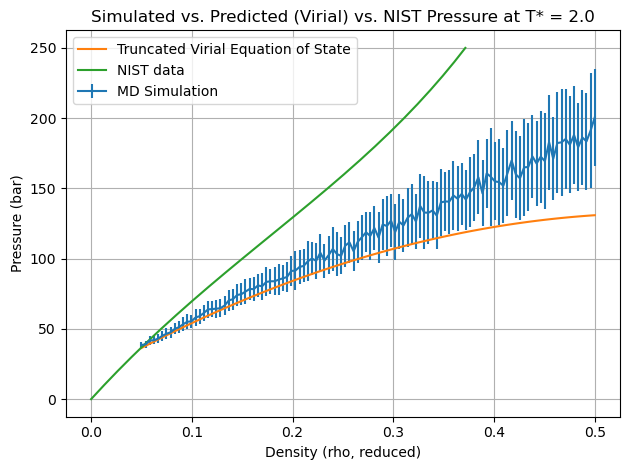

In [67]:
rho_vals = np.linspace(0.05, 0.5, 110)

plt.figure()
plt.errorbar(
    rho_vals, 
    sim_p_bar, 
    sim_err_bar,
    label='MD Simulation'
)

plt.plot(
    rho_vals, 
    virial_p_bar, 
    label='Truncated Virial Equation of State'
)

plt.plot(
    NIST_density_star, 
    NIST_pressure, 
    label='NIST data'
)

plt.xlabel("Density (rho, reduced)")
plt.ylabel("Pressure (bar)")
plt.title("Simulated vs. Predicted (Virial) vs. NIST Pressure at T* = 2.0")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [68]:
print("Density range:", rho_vals.min(), "to", rho_vals.max())
print("Number of MD results:", len(sim_p_bar))
print("Number of virial results:", len(virial_p_bar))
print("Number of MD errors:", len(sim_err_bar))

Density range: 0.05 to 0.5
Number of MD results: 110
Number of virial results: 110
Number of MD errors: 110


Comparing the NIST experimental data to the MD simulations, the MDS provide a better overall prediction across the density range. This is because MD accounts for intermolecular forces directly, whereas the truncated virial equation only includes the second virial coefficient and becomes less reliable at higher densities.

# Section Three - Chemical Potential

When we studied the canonical ensemble, we found that the chemical potential could be expressed as:

$$ \frac{\mu}{T} = - \left (  \frac{\partial S}{\partial N} \right )_{V,E}$$

In the microcanonical ensemble, the entropy $S$ is related to the number of accessible states $S = k_B ln\Omega(N,V,E)$. It can be shown that in order to calculate the above derivative, one needs to compute $\Omega(N+1,V,E)/\Omega(N,V,E)$, which would be very difficult in ordinary simulations.

An alternative approach was suggested by Benjamin Widom [*J. Chem. Phys.* **39**, 2808-2812 (1963)].  Once an $NVE$ simulation has reached equilibrium, a virtual test particle is placed randomly into the fluid and the change in total internal energy $\Delta U$ is calculated. The test particle is then removed before the simulation is allowed to integrate to the next time step. This process is then repeated throughout the simulation and the "excess" chemical potential is calculated from the following equation:

$$ \mu^{ex} = \mu - \mu^{ideal} = -k_B \langle T \rangle ln \left [ \langle T \rangle^{-3/2} \langle T^{3/2} e^{-\Delta U/k_B T} \rangle \right ] $$





## Part Ten

Using the ideas from the Widom method above, modify the MD code above to calculate the chemical potential of methane (in SI units) at $\rho^* = 0.1$ and $T^* = 2.0$. Perform your calculations at a variety of system sizes, e.g. $N = 100, 200, 500, 1000$. Note that the simulation time scales as $N^2$ so the larger simulations may take some time. Comment on your results. Note that you will need to calculate the ideal component, $\mu^{ideal}$ analytically.

In [76]:
import numpy as np #imports numpy library
from numba import double, jit, types #imports numba tools to turn python from interpreter to compiler to speed up run time
import matplotlib.pyplot as plt #imports Matplotlib for plotting and visualising simulation results

def getParams(rho): #defines a function that calculates simulation parameters using density
    params = np.zeros(4) #creates an array of four parameters initially set at zero
    rCut = 2.5 #defines the cut-off distance, beyond this distance any particle interactions are neglected
    params[0] = rCut #stores the cut-off distance of the first element
    params[1] = rCut*rCut  #stores and calculates the squared of the cut-off distance
    rc2i = 1.0/params[1] #calculates the inverse of the squared cut-off distance
    rc6i = rc2i*rc2i*rc2i #calculates the sixth power of the cut-off distance
    params[2] = rc6i*(rc6i-1.0) #stores and calculates the twelveth power of the cut-off distance subtracted by the sixth 
    params[3] = (16.0/3.0)*np.pi*rho*rho*((2.0/3.0)*(np.power(rCut,-9.0))-np.power(rCut,-3.0)) #stores and calculates a density-dependent correction term using the cutoff distance and its inverse third and ninth powers 
    return params #returs the array containing the four calculated simulation parameters

def getData(): #defines a function that initiliases the dictionary used to store simulation data
    data = {} #creates an empty python dictionary to store simulation results
    data['eKin'] = [] #creates an empty list to store kinetic energy at each simulation step
    data['ePot'] = [] #creates an empty list to store potential energy at each simulation step
    data['pres'] = [] #creates an empty list to store the pressure calculated during simulation
    data['temp'] = [] #creates an empty list to store the temperature at each simulation step
    data['time'] = [] #creates an empty list to store the simulation time at each time step
    data['widom_T'] = [] # Creates an empty list to store the instantaneous temperatures at each Widom insertion
    data['widom_weight'] = [] # Creates an empty list to store the temperature-weighted Boltzmann factors for each insertion

    return data #returns the dictionary containing the empty lists ready to store simulation results
    

@jit(types.Tuple((double, double))(double[:,:]),nopython=True) #uses numba to accelerate the function
def getKinetic(V): #defines a function that calculates kinetic energy and temperature from particle velocities
    
    n_atoms = len(V[0]) #determines the total number of atoms by counting the velocity components in the x-direction
    kTot = 0.0 #sets the total kinetic energy accumulator initially zero
    temp = 0.0 #sets the temperature initially zero
    
    for i in range(n_atoms): #creates a loop and loops through every atom
        kTot += V[0,i]*V[0,i] + V[1,i]*V[1,i] + V[2,i]*V[2,i] #adds the squared velocity components in the x,y, and z directions to the total kinetic accumulator 
        
    kTot = kTot / 2 #calculates the total kinetic energy(assuming particle mass = 1) by dividing by two
    
    temp = (2 * kTot) / (3 * n_atoms) #calculates the temperature from the kinetic energy and number of atoms(assuming that the boltzman constant = 1)
    
    return kTot,temp #returrns the total kinetic energy and temperature
    

@jit(types.Tuple((double[:,:], double, double))(double[:,:], double[:], double[:]),nopython=True)
def lennardjones(U, box, params): #defines a function to calculate the Lennard Jones forces, potential and virial
    
    n_atoms = len(U[0]) #determines the total number of atoms using the x-coordinate

    f = np.zeros((3, n_atoms)) #ceates an array of zeros to store the x, y and z force componenets of each atom

    ePot = 0.0 #sets the potential energy initially at zero
    vir = np.zeros(3) #creates an array of the x, y and z direction to accumulate the virial contributions
    virTotal = 0.0 #sets the total virial contribution to zero

    for i in range(n_atoms): #creates a loop and loops through every atom as the first particle in an interacting pair
        for j in range(n_atoms): #creates a loop and loops through every atom again to identify possible interacting particle pairs
            
            if i > j: #allows 2 particles to collide only once, does not consider secondary and tertiary collisions from the sme 2 particles

                dx  = U[0,j] - U[0,i] #Calculates the separation between particles j and i in the x-direction
                dy  = U[1,j] - U[1,i] #Calculates the separation between particles j and i in the y-direction
                dz  = U[2,j] - U[2,i] #Calculates the separation between particles j and i in the z-direction

                dx  -= box[0] * np.rint(dx/box[0]) #Applies the minimum image convention in x to account for periodic boundary conditions 
                dy  -= box[1] * np.rint(dy/box[1]) #Applies the minimum image convention in yto account for periodic boundary conditions
                dz  -= box[2] * np.rint(dz/box[2]) #Applies the minimum image convention in x to account for periodic boundary conditions

                r2 = dx*dx + dy*dy + dz*dz #calculates the squared distance of the separation of 2 particles

                if(r2 < params[1]): #creates a conditional to check whether particles are closer than the squared off the cut-off distance
                
                    r2i = 1.0 / r2 #calculates the inverse of the squared separation distance
                    r6i = r2i*r2i*r2i #calculates the sixth power of the inverse square se[aration distance

                    ePot = ePot + r6i*(r6i-1.0) - params[2] #calculates the pair potential contribution, including a correction that shifts the potential to zero at the cutoff distance

                    ftmp = 48.0 * r6i*(r6i- 0.5) * r2i #calculates the scalar force by differentiating the negative potential with respect to distance
                    
                    fx = ftmp * dx #calculates the x component of the force between the 2 particles
                    fy = ftmp * dy #calculates the y component of the force between the 2 particles
                    fz = ftmp * dz #calculates the z component of the force between the 2 particles
                    
                    f[0,i] -= fx #updates the x component of the force on particle i
                    f[1,i] -= fy #updates the y component of the force on particle i
                    f[2,i] -= fz #updates the z component of the force on particle i
                    f[0,j] += fx #updates the x component of the force on particle j with the equal and opposite force
                    f[1,j] += fy #updates the y component of the force on particle j with the equal and opposite force
                    f[2,j] += fz #updates the z component of the force on particle j with the equal and opposite force
                    
                    vir[0] += fx * dx #accumulates the x direction virial contribution from this particular pair
                    vir[1] += fy * dy #accumulates the y direction virial contribution from this particular pair
                    vir[2] += fz * dz #accumulates the z direction virial contribution from this particular pair
                                 
    ePot = ePot * 4.0 #multiplies the pair potential contribution by 4 to obtain the Lennard-Jones potential energy in standard reduced units
    virTotal = np.mean(vir) #Calculates the average of the three directional virial contributions
    return f,ePot,virTotal #returns the force, potential energy, and the average virial contributions



@jit(double(double[:,:], double[:], double[:]), nopython=True) # Compiles this function with Numba to make the insertion calculations faster
def widom_insertion(pos, box, params): # Defines a function that calculates the energy change when a test methane molecule is inserted

    test_pos = np.random.random(3) * box # Generates a random x, y, z position inside the simulation box

    delta_U = 0.0 # Initialises the total insertion energy change at zero

    n_atoms = len(pos[0]) # Counts the number of real particles already in the simulation

    for j in range(n_atoms): # Loops through every existing particle to calculate its interaction with the test particle

        dx = test_pos[0] - pos[0,j] # Calculates the separation in the x direction
        dy = test_pos[1] - pos[1,j] # Calculates the separation in the y direction
        dz = test_pos[2] - pos[2,j] # Calculates the separation in the z direction

        dx -= box[0] * np.rint(dx / box[0]) # Applies periodic boundary conditions in x
        dy -= box[1] * np.rint(dy / box[1]) # Applies periodic boundary conditions in y
        dz -= box[2] * np.rint(dz / box[2]) # Applies periodic boundary conditions in z

        r2 = dx*dx + dy*dy + dz*dz # Calculates the squared distance between the test particle and existing particle

        if r2 < 1e-12: # Checks whether the test particle overlaps almost exactly with an existing particle
            return 1e100 # Assigns an extremely large repulsive energy to this practically impossible insertion

        if r2 < params[1]: # Checks whether the particles are within the Lennard-Jones cutoff distance

            r2i = 1.0 / r2 # Calculates the inverse squared distance
            r6i = r2i*r2i*r2i # Calculates the inverse sixth power of the distance

            delta_U += 4.0 * (r6i*(r6i-1.0) - params[2]) # Adds the shifted Lennard-Jones interaction energy to the total insertion energy

    return delta_U # Returns the total potential energy change caused by inserting the test particle



def initialize_positions(n_atoms, rho): #defines a function to initialise the position of all atoms using the number of atoms and density
    
    pos = np.zeros((3, n_atoms)) #creates an array of 4 parameters, 3 of them are initially zero to store the x, y and z coordinates of every atom
    nPerDim = int(np.ceil(pow(n_atoms,(1.0/3.0)))) #calculates the number of grid points needed along each dimension to accomodate all atoms
    vol = n_atoms/rho #calculates the total simulation volume
    lenWhole = np.power(vol,(1.0/3.0)) #Calculates the side length of the cubic simulation box using L = V^(1/3)
    
    counter = 0 #initiliases a counter to keep track of how many atoms have been assigned positions
    for i in range(0,nPerDim): #creates a loop and loops through the grid positions in the x direction
        for j in range(0,nPerDim): #creates a loop and loops through the grid positions in the y direction
            for k in range(0,nPerDim): #creates a loop and loops through the grid positions in the z direction
                if (counter < n_atoms): #checks that the total number of assignes positions have not exceeded the total number of atoms
                    pos[0,counter] = (i+0.5)*lenWhole/nPerDim #assigns the x coordinate of the current atom, placing it at the centre of its grid cell
                    pos[1,counter] = (j+0.5)*lenWhole/nPerDim #assigns the y coordinate of the current atom, placing it at the centre of its grid cell
                    pos[2,counter] = (k+0.5)*lenWhole/nPerDim #assigns the z coordinate of the current atom, placing it at the centre of its grid cell
                    counter += 1 #increases the counter after succesfully assigning a particle position
    return pos #returns the array containing the initial position of all atoms

def initialize_box(n_atoms, rho): #defines a function that initialiazes the simulation box using the number of atoms and number density
    
    box = np.zeros(3) #creates an array of 3 elements to store the box lengths
    vol = n_atoms/rho #calculates the total simulation volume
    lenWhole = np.power(vol,(1.0/3.0)) #Calculates the side length of the cubic simulation box using L = V^(1/3)
    box[0] = box[1] = box[2] = lenWhole #assigns the box length to x = y = z
    return box #returns the box dimensions

def initialize_velocities(n_atoms,temp): #defines a function to initialize the velocity of all atoms using the number of atoms and temperature

    vel = np.random.normal(0.0,np.sqrt(temp),(3,n_atoms)) #creates random velocity of atoms from a Gaussian distribution with mean zero and standard deviation sqrt(T), for all three directions and all atoms
    mean = np.mean(vel,axis=1) #calculates the average velocities across all atoms in each direction
    for i in range(3): #creates a loop and loops through the x, y and z
        vel[i] -= mean[i] #subtracts the average velocity in each direction to eliminate the overall centre of mass motion
    return vel #returns the initial velocity array of all atoms

@jit(double[:,:](double[:,:], double, double),nopython=True)
def scale_velocities(vel,target,temp): #defines a function that rescales velocities to achieve the target temperature

    factor = np.sqrt(target/temp) #calculates the scaling factor using the square root of the ratio between target and current temperature
    return vel*factor #returns the adjusted velocities

def runSimulation(temperature, n_atoms, rho, n_steps_eq, n_steps_prod, widom_interval=10): # Adds a new parameter controlling how frequently we perform Widom insertions
    
    pos = initialize_positions(n_atoms, rho) #sets the intial position of all atoms on the 3D grid
    box = initialize_box(n_atoms, rho) #generates the dimensions of the cube
    vel = initialize_velocities(n_atoms, temperature) #generates the initial velocities corresponding to the temperature
    params = getParams(rho) #Calculates and stores the Lennard-Jones parameters and density-dependent corrections
    data= getData() #Creates an empty dictionary to store simulation results such as energy, temperature, pressure and time
    
    
    if (box[0] < 2*params[0]): #checks whether the box length is less than twice the cut-off distance
        print("Box size too small. Try adding more atoms or reducing the density.") #if it is, it prints the size is smaller than it should
        return #stops the simulation if the box dimensions are unsuitable
    
    
    n_steps_tot = n_steps_eq + n_steps_prod #total steps is the accumulation of equilibration and production steps
    blockTemp = 500 #defines the number of simulation steps between temperature rescaling operations
    blockData = 50 #defines the number of simulation steps between data recording operations
    dt = 0.0005 #sets the simulation time step
    
    force,ePot,virial = lennardjones(pos,box,params) #calculates the initial forces, potential energies and virial using the lennard jones parameters
    tempBlock = 0.0 #initialises an accumulator to zero, used to sum the instantaneous temperatures over 500 simulation steps during equilibration
    presBlock = 0.0 #initialises an accumulator to zero, used to sum the calculated pressure values over 50 simulation steps before calculating their average
    
    print("Starting equilibration...") #displays a message indicating that the equilibration stage is starting
    
    for i in range(n_steps_tot): #starts the main simulation loop and repeats the molecular dynamics calculations for every time step
        
        if i == n_steps_eq: #checks whether the equilibration steps have finished
            print("Finished equilibration, beginning production...") # if equilibration finished, displays a message that it has and it begines production
        
        
        pos += vel * dt + 0.5 * force * dt * dt #updates the atoms positions using the velocity-Verlet integration equation  
        
        force0 = force[:] #creates a copy of the old forces before calculating the new forces at the updated atom positions
        
        force,ePot,virial = lennardjones(pos, box, params)  #recalculates forces, potential energy and virial using the updated atom positions
        
        vel += 0.5 * (force + force0) * dt #updates atom velocities using the average of the old and new forces (velocity-Verlet algorithm, assuming unit mass)
     
        kTot,temp = getKinetic(vel) #calculates the total kinetic energy and instanteneous temperature using the updated velocities 
        
        if i >= n_steps_eq and (i - n_steps_eq) % widom_interval == 0: # Checks that equilibration is finished and the required number of production steps has passed

            delta_U = widom_insertion(pos, box, params) # Calculates the energy change from inserting one imaginary methane molecule

            data['widom_T'].append(temp) # Stores the instantaneous temperature associated with this insertion

            weight = temp**1.5 * np.exp(-delta_U/temp) # Calculates the temperature-weighted Boltzmann factor from the Widom equation

            data['widom_weight'].append(weight) # Stores the calculated insertion weight for later averaging
        
        tempBlock += temp #accumulates the current temperature for the current temperature-rescaling block

        presBlock += (rho*temp) + (virial/(box[0]*box[1]*box[2])) + params[3] #accumulates the pressure contribution from particle motion, interparticle forces and the density-dependent tail correction
        
        if (i+1)%blockData == 0: #checks whether the current simulation step is a multiple of the data-recording interval
            data['eKin'].append(kTot) #stores the current total kinetic energy in the results dictionary
            data['ePot'].append(ePot) #stores the current total potential energy in the results dictionary
            data['temp'].append(temp) #stores the current instantaneous temperature in the results dictionary
            data['pres'].append(presBlock/blockData) #stores the average pressure over the last data-recording block
            data['time'].append((i+1)*dt) #stores the elapsed simulation time corresponding to the current simulation step
            presBlock = 0.0 #resets the accumulated pressure to zero for the next data-recording block
                                   
        if (i+1)%blockTemp == 0 and i < n_steps_eq: #checks whether 500 steps have passed and whether the simulation is still in the equilibration stage
            avgTemp = tempBlock/blockTemp #calculates the average temperature over the last temperature-rescaling block
            vel = scale_velocities(vel,temperature,avgTemp) #rescales atom velocities to bring the system closer to the target temperature
            tempBlock = 0.0 #resets the accumulated temperature to zero for the next temperature-rescaling block
     
        if (i+1)%5000 == 0 and (i+1) <= n_steps_eq: #checks whether 5000 steps have passed during equilibration
            print("{0:.2f}% done".format((i+1)*100/n_steps_eq)) #calculates and displays the percentage of equilibration completed
            
        if (i+1)%5000 == 0 and (i+1) > n_steps_eq: #checks whether 5000 steps have passed during production
            print("{0:.2f}% done".format((i+1-n_steps_eq)*100/n_steps_prod)) #calculates and displays the percentage of production completed
    
    return data #returns the dictionary containing all the recorded simulation results


In [77]:
# Physical constants
kB = 1.380649e-23 # Boltzmann constant in J/K
NA = 6.02214076e23 # Avogadro's constant in molecules/mol
h = 6.62607015e-34 # Planck's constant in J.s

# Methane properties
sigma = 3.73e-10 # Methane Lennard-Jones diameter in metres (check against your assignment's chosen model)
epsilon_over_kB = 147.9 # Methane Lennard-Jones energy parameter divided by Boltzmann's constant, in K
molar_mass = 16.043e-3 # Methane molar mass in kg/mol

# Simulation conditions
T_star = 2.0 # Reduced temperature specified in Part Ten
rho_star = 0.1 # Reduced number density specified in Part Ten

# Convert reduced temperature into Kelvin
T_K = T_star * epsilon_over_kB # Calculates the actual temperature in Kelvin

# Convert reduced density into number density
rho_SI = rho_star / sigma**3 # Calculates molecules per cubic metre

# Calculate the mass of one methane molecule
m = molar_mass / NA # Converts molar mass into mass per molecule

# Calculate the thermal de Broglie wavelength
lambda_th = h / np.sqrt(2*np.pi*m*kB*T_K) # Calculates the characteristic quantum wavelength of methane

# Calculate ideal chemical potential per molecule
mu_ideal = kB*T_K*np.log(rho_SI*lambda_th**3) # Calculates the classical ideal-gas chemical potential in J per molecule

# Convert to molar units
mu_ideal_molar = mu_ideal * NA # Converts J per molecule into J/mol

print("Temperature:", T_K, "K") # Displays the actual temperature
print("Number density:", rho_SI, "molecules/m^3") # Displays the actual number density
print("Ideal chemical potential:", mu_ideal_molar, "J/mol") # Displays the ideal chemical potential


Temperature: 295.8 K
Number density: 1.926963571543735e+27 molecules/m^3
Ideal chemical potential: -25503.704314539344 J/mol


In [78]:

def calculate_chemical_potential_uncertainty(data, n_blocks=20):

    # Convert the stored Widom data into NumPy arrays
    temperatures = np.array(data['widom_T'])
    weights = np.array(data['widom_weight'])

    # Find the total number of insertion measurements
    n_measurements = len(weights)

    # Calculate the number of measurements in each block
    block_size = n_measurements // n_blocks

    # Check that we have enough measurements
    if block_size < 2:
        raise ValueError("Not enough Widom insertions for block averaging")

    # Store the chemical potential calculated from each block
    block_mu = []

    # Loop through each block
    for i in range(n_blocks):

        # Find the beginning and end of the current block
        start = i * block_size
        end = start + block_size

        # Extract the temperatures and weights for this block
        T_block = temperatures[start:end]
        weight_block = weights[start:end]

        # Calculate the average temperature for this block
        mean_T = np.mean(T_block)

        # Calculate the average Boltzmann weight for this block
        mean_weight = np.mean(weight_block)

        # Calculate the excess chemical potential for this block
        mu_block = -mean_T * np.log(
            mean_weight / mean_T**1.5
        )

        # Store the result
        block_mu.append(mu_block)

    # Convert block results into a NumPy array
    block_mu = np.array(block_mu)

    # Calculate the average excess chemical potential across blocks
    mu_mean = np.mean(block_mu)

    # Calculate the standard deviation between blocks
    mu_std = np.std(block_mu, ddof=1)

    # Calculate the standard error of the mean
    mu_error = mu_std / np.sqrt(n_blocks)

    # Return the mean, standard deviation and standard error
    return mu_mean, mu_std, mu_error


In [79]:

# Methane Lennard-Jones energy scale
epsilon = kB * epsilon_over_kB

# System sizes
system_sizes = [100, 200, 500, 1000]

# Store final results
results = []

for N in system_sizes:

    print("\nRunning simulation with", N, "particles")

    # Run the MD simulation
    data = runSimulation(
        temperature=2.0,
        n_atoms=N,
        rho=0.1,
        n_steps_eq=5000,
        n_steps_prod=10000,
        widom_interval=10
    )

    # Calculate excess chemical potential and its uncertainty
    mu_excess_star, mu_std_star, mu_error_star = calculate_chemical_potential_uncertainty(
        data, n_blocks=20
    )

    # Convert reduced chemical potentials into J/mol
    mu_excess = mu_excess_star * epsilon * NA
    mu_std = mu_std_star * epsilon * NA
    mu_error = mu_error_star * epsilon * NA

    # Calculate total chemical potential
    mu_total = mu_ideal_molar + mu_excess

    # Store all results
    results.append([
        N,
        mu_ideal_molar,
        mu_excess,
        mu_total,
        mu_std,
        mu_error
    ])

    print(f"Excess chemical potential: {mu_excess:.5g} ± {mu_error:.5g} J/mol")
    print(f"Total chemical potential: {mu_total:.5g} J/mol")


# Convert results into NumPy array
results = np.array(results)

# Display final results
print("\nFINAL RESULTS")
print("-" * 105)

print(
    f"{'N':>8} | {'Ideal':>13} | {'Excess':>13} | "
    f"{'Total':>13} | {'Std Dev':>13} | {'Std Error':>13}"
)

print("-" * 105)

for row in results:

    print(
        f"{int(row[0]):8d} | "
        f"{row[1]:13.5g} | "
        f"{row[2]:13.5g} | "
        f"{row[3]:13.5g} | "
        f"{row[4]:13.5g} | "
        f"{row[5]:13.5g}"
    )



Running simulation with 100 particles
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Excess chemical potential: -285.95 ± 77.065 J/mol
Total chemical potential: -25790 J/mol

Running simulation with 200 particles
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Excess chemical potential: -255.52 ± 67.776 J/mol
Total chemical potential: -25759 J/mol

Running simulation with 500 particles
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Excess chemical potential: -394.61 ± 58.276 J/mol
Total chemical potential: -25898 J/mol

Running simulation with 1000 particles
Starting equilibration...
100.00% done
Finished equilibration, beginning production...
50.00% done
100.00% done
Excess chemical potential: -196.53 ± 72.267 J/mol
Total chemical potential: -25700 J/mol

FINAL RESULTS
------------------------

The total chemical potential remains relatively consistent as the system size increases from $N=100$ to $N=1000$, ranging from approximately $-25.70$ to $-25.90$ kJ/mol. The ideal contribution remains constant at approximately $-25.50$ kJ/mol, while the excess chemical potential varies between $-196.53$ and $-394.61$ J/mol. No clear convergence trend is observed with increasing system size. This variation is likely due to statistical fluctuations in the Widom insertion method, as reflected by the relatively large standard errors. Longer simulations and more insertion attempts could improve the statistical accuracy of the results.